# ASSIGNMENT No: 04
## Molecular Docking and Virtual Screening

### Aim
To perform molecular docking simulations to predict the binding affinity between a protein target and small-molecule ligands, and to demonstrate virtual screening.

### Software
- Python / Jupyter Notebook
- AutoDock Vina
- Meeko
- RDKit
- PyMOL or UCSF Chimera (optional, for visualization)

### Dataset / Structures
- **Protein:** HIV-1 protease, PDB ID **1HVR**
- **Reference binding site:** co-crystallized ligand **XK2**
- **Screening ligands:** selected known HIV-protease inhibitor molecules downloaded from PubChem.

> This is an educational computational experiment. Docking scores are predictions and should not be interpreted as experimental binding affinities or proof of drug efficacy.

## Theory

Molecular docking predicts how a small molecule (ligand) can bind inside a target protein's binding site. A docking program explores ligand poses and uses a scoring function to estimate the favorability of each pose.

A more favorable AutoDock Vina score is generally a **more negative predicted binding free-energy score (kcal/mol)**. Docking is therefore useful for ranking compounds during virtual screening, but the scores are computational predictions and require experimental validation.

Virtual screening applies the docking workflow to multiple compounds and ranks them according to their predicted binding scores.

The selected PDB structure, **1HVR**, is an experimentally determined HIV-1 protease structure containing ligand XK2. The RCSB record reports an X-ray structure at 1.80 Å resolution and identifies XK2 as the unique bound small molecule.

In [ ]:
# Step 1: Install the required packages in Google Colab
# IMPORTANT: Do not install the Python `vina` package here.
# We use the official AutoDock Vina Linux executable instead.
# `gemmi` is installed explicitly because current Meeko imports it.

%pip install -q -U meeko gemmi prody rdkit matplotlib "pandas==2.2.3" "requests==2.32.4"

!wget -q -O vina_1.2.7_linux_x86_64 https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v1.2.7/vina_1.2.7_linux_x86_64
!chmod +x vina_1.2.7_linux_x86_64
!./vina_1.2.7_linux_x86_64 --version

import meeko, gemmi, rdkit
print("Meeko: OK")
print("Gemmi: OK")
print("RDKit:", rdkit.__version__)


AutoDock Vina v1.2.7
Meeko: OK
Gemmi: OK
RDKit: 2026.03.6


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Why this version does not `pip install vina`

The Colab runtime can use a newer Python version than the versions supported by the published Vina Python wheels. Instead of compiling Vina from source, this notebook downloads the official AutoDock Vina Linux executable.

Current Meeko also imports the `gemmi` package, so `gemmi` is installed explicitly. Pandas and Requests are pinned to the versions expected by Google Colab to avoid dependency-conflict warnings.


In [ ]:
# Step 2: Import libraries
import os
import subprocess
import sys
import shutil
import requests
import pandas as pd
import numpy as np
from pathlib import Path

WORKDIR = Path("assignment04_docking")
WORKDIR.mkdir(exist_ok=True)

VINA = Path("vina_1.2.7_linux_x86_64").resolve()

print("Working directory:", WORKDIR.resolve())
print("Vina:", VINA)
print("Meeko receptor tool:", shutil.which("mk_prepare_receptor.py"))
print("Meeko ligand tool:", shutil.which("mk_prepare_ligand.py"))

if not VINA.exists():
    raise FileNotFoundError("Vina executable was not downloaded.")

Working directory: /content/assignment04_docking
Vina: /content/vina_1.2.7_linux_x86_64
Meeko receptor tool: /usr/local/bin/mk_prepare_receptor.py
Meeko ligand tool: /usr/local/bin/mk_prepare_ligand.py


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 3: Download the protein structure from RCSB PDB

pdb_id = "1HVR"
pdb_url = f"https://files.rcsb.org/download/{pdb_id}.pdb"
pdb_path = WORKDIR / f"{pdb_id}.pdb"

response = requests.get(pdb_url, timeout=60)
response.raise_for_status()
pdb_path.write_text(response.text)

print("Downloaded:", pdb_path)
print("Size:", pdb_path.stat().st_size, "bytes")

Downloaded: assignment04_docking/1HVR.pdb
Size: 190431 bytes


In [ ]:
# Step 4: Extract the protein and reference ligand (XK2)
# We retain ATOM records for the protein and HETATM records belonging to XK2.

protein_path = WORKDIR / "1HVR_protein.pdb"
reference_ligand_path = WORKDIR / "XK2_reference.pdb"

protein_lines = []
ligand_lines = []

for line in pdb_path.read_text().splitlines(True):
    record = line[0:6].strip()
    resname = line[17:20].strip()

    if record == "ATOM":
        protein_lines.append(line)

    if record == "HETATM" and resname == "XK2":
        ligand_lines.append(line)

protein_path.write_text("".join(protein_lines) + "END\n")
reference_ligand_path.write_text("".join(ligand_lines) + "END\n")

print("Protein:", protein_path)
print("Reference ligand:", reference_ligand_path)
print("Reference ligand atoms:", len(ligand_lines))

Protein: assignment04_docking/1HVR_protein.pdb
Reference ligand: assignment04_docking/XK2_reference.pdb
Reference ligand atoms: 46


## Step 5: Determine the docking box

The docking box is centered on the experimentally observed XK2 binding site. We calculate the center of the XK2 coordinates and add padding around the reference ligand.

In [ ]:
# Calculate center of the reference ligand

coords = []

for line in ligand_lines:
    x = float(line[30:38])
    y = float(line[38:46])
    z = float(line[46:54])
    coords.append([x, y, z])

coords = np.array(coords)
center = coords.mean(axis=0)

# Add enough space around the ligand for docking
box_size = np.array([24.0, 24.0, 24.0])

print("Docking box center:")
print("X =", round(center[0], 3))
print("Y =", round(center[1], 3))
print("Z =", round(center[2], 3))
print("Box size =", box_size.tolist())

Docking box center:
X = -9.192
Y = 15.906
Z = 27.946
Box size = [24.0, 24.0, 24.0]


## Step 6: Prepare the receptor for AutoDock Vina

Meeko's `mk_prepare_receptor.py` converts the protein structure into PDBQT format and can generate a Vina-style box configuration. The original manual recommends preparing the protein by removing unnecessary waters/ligands and assigning the required docking parameters.

In [ ]:
# Prepare receptor PDBQT using Meeko
if shutil.which("mk_prepare_receptor.py") is None:
    raise RuntimeError("mk_prepare_receptor.py was not found. Re-run Step 1.")

receptor_prefix = WORKDIR / "1HVR_receptor"

cmd = [
    "mk_prepare_receptor.py",
    "-i", str(protein_path),
    "-o", str(receptor_prefix),
    "-p",
    "-v",
    "--box_center", str(center[0]), str(center[1]), str(center[2]),
    "--box_size", str(box_size[0]), str(box_size[1]), str(box_size[2])
]

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Receptor preparation failed.")

receptor_pdbqt = WORKDIR / "1HVR_receptor.pdbqt"

if not receptor_pdbqt.exists():
    raise FileNotFoundError(receptor_pdbqt)

print("Prepared receptor:", receptor_pdbqt)

Template padding will be used.
 gasteiger charges will be read from template file 
 

Files written:
  assignment04_docking/1HVR_receptor.pdbqt <-- static (i.e., rigid) receptor input file
assignment04_docking/1HVR_receptor.box.txt <-- Vina-style box dimension file
assignment04_docking/1HVR_receptor.box.pdb <-- PDB file to visualize the grid box

@> 1826 atoms and 1 coordinate set(s) were parsed in 0.01s.

Prepared receptor: assignment04_docking/1HVR_receptor.pdbqt


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Step 7: Prepare screening ligands

Four known HIV-protease inhibitors are used as a small demonstration library:

- Indinavir
- Ritonavir
- Saquinavir
- Nelfinavir

Their 3D structures are downloaded from PubChem and converted to PDBQT using Meeko.

In [ ]:
# PubChem CIDs for the screening library
from rdkit import Chem
from rdkit.Chem import AllChem

ligands = {
    "Indinavir": 5362440,
    "Ritonavir": 392622,
    "Saquinavir": 441243,
    "Nelfinavir": 451104
}

ligand_files = {}

for name, cid in ligands.items():
    sdf_path = WORKDIR / f"{name.lower()}_3d.sdf"

    # Try downloading the PubChem 3D structure
    url_3d = (
        f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
        f"compound/cid/{cid}/SDF?record_type=3d"
    )

    r = requests.get(url_3d, timeout=60)

    if r.status_code == 200:
        sdf_path.write_text(r.text)
        ligand_files[name] = sdf_path
        print(name, "downloaded ->", sdf_path)

    else:
        # Fallback: download 2D structure and generate 3D coordinates
        print(name, "3D structure unavailable. Generating 3D structure...")

        url_2d = (
            f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
            f"compound/cid/{cid}/SDF"
        )

        r2 = requests.get(url_2d, timeout=60)
        r2.raise_for_status()

        mol = Chem.MolFromMolBlock(
            r2.text,
            removeHs=False
        )

        if mol is None:
            raise RuntimeError(f"Could not read {name} from PubChem.")

        mol = Chem.AddHs(mol)

        # Generate 3D coordinates
        params = AllChem.ETKDGv3()
        params.randomSeed = 42

        status = AllChem.EmbedMolecule(mol, params)

        if status != 0:
            print("ETKDG failed, trying random coordinates...")
            status = AllChem.EmbedMolecule(
                mol,
                useRandomCoords=True,
                randomSeed=42
            )

        if status != 0:
            raise RuntimeError(
                f"Could not generate 3D coordinates for {name}."
            )

        # Optimize geometry
        try:
            AllChem.MMFFOptimizeMolecule(
                mol,
                maxIters=500
            )
        except:
            AllChem.UFFOptimizeMolecule(
                mol,
                maxIters=500
            )

# Keep explicit hydrogens for Meeko
        writer = Chem.SDWriter(str(sdf_path))
        writer.write(mol)
        writer.close()

        ligand_files[name] = sdf_path

        print(name, "generated ->", sdf_path)

print("\nAll ligands are ready.")

Indinavir downloaded -> assignment04_docking/indinavir_3d.sdf
Ritonavir 3D structure unavailable. Generating 3D structure...
Ritonavir generated -> assignment04_docking/ritonavir_3d.sdf
Saquinavir 3D structure unavailable. Generating 3D structure...
Saquinavir generated -> assignment04_docking/saquinavir_3d.sdf
Nelfinavir downloaded -> assignment04_docking/nelfinavir_3d.sdf

All ligands are ready.


In [ ]:
# Convert ligands to PDBQT using Meeko
if shutil.which("mk_prepare_ligand.py") is None:
    raise RuntimeError("mk_prepare_ligand.py was not found. Re-run Step 1.")

prepared_ligands = {}

for name, sdf_path in ligand_files.items():
    pdbqt_path = WORKDIR / f"{name.lower()}.pdbqt"

    cmd = [
        "mk_prepare_ligand.py",
        "-i", str(sdf_path),
        "-o", str(pdbqt_path)
    ]

    result = subprocess.run(cmd, capture_output=True, text=True)

    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"Ligand preparation failed for {name}")

    prepared_ligands[name] = pdbqt_path
    print("Prepared:", name)

print("Prepared ligands:", list(prepared_ligands))

Prepared: Indinavir


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Prepared: Ritonavir


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Prepared: Saquinavir


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Prepared: Nelfinavir
Prepared ligands: ['Indinavir', 'Ritonavir', 'Saquinavir', 'Nelfinavir']


## Step 8: Perform molecular docking

AutoDock Vina is used to dock each ligand into the same binding pocket.

The best pose from each docking run is ranked using the predicted affinity score. More negative scores indicate more favorable predicted binding under the scoring model.

In [ ]:
# Dock each ligand using the AutoDock Vina command-line executable
# This performs REAL molecular docking; no scores are simulated.

results = []

for name, ligand_path in prepared_ligands.items():
    print(f"\nDocking {name}...")

    out_path = WORKDIR / f"{name.lower()}_docked.pdbqt"
    log_path = WORKDIR / f"{name.lower()}_vina.log"

    cmd = [
        str(VINA),
        "--receptor", str(receptor_pdbqt),
        "--ligand", str(ligand_path),
        "--center_x", str(center[0]),
        "--center_y", str(center[1]),
        "--center_z", str(center[2]),
        "--size_x", str(box_size[0]),
        "--size_y", str(box_size[1]),
        "--size_z", str(box_size[2]),
        "--exhaustiveness", "8",
        "--num_modes", "5",
        "--out", str(out_path),
    ]

    result = subprocess.run(cmd, capture_output=True, text=True)

    log_path.write_text(result.stdout + "\n" + result.stderr, encoding="utf-8")

    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"Docking failed for {name}")

    affinity = None

    # Parse the first ranked pose from Vina's stdout table.
    for line in result.stdout.splitlines():
        parts = line.strip().split()
        if len(parts) >= 2 and parts[0] == "1":
            try:
                affinity = float(parts[1])
                break
            except ValueError:
                pass

    # Fallback: parse the first REMARK VINA RESULT in the output PDBQT.
    if affinity is None and out_path.exists():
        for line in out_path.read_text(errors="ignore").splitlines():
            if line.startswith("REMARK VINA RESULT:"):
                parts = line.split()
                try:
                    affinity = float(parts[3])
                    break
                except (IndexError, ValueError):
                    pass

    if affinity is None:
        raise RuntimeError(
            f"Could not extract the Vina affinity for {name}. "
            f"Check {log_path}."
        )

    print(f"Best predicted affinity: {affinity:.3f} kcal/mol")

    results.append({
        "Ligand": name,
        "Best Affinity (kcal/mol)": affinity,
        "Docked Pose": str(out_path)
    })

results_df = pd.DataFrame(results).sort_values(
    "Best Affinity (kcal/mol)"
).reset_index(drop=True)

print("\nVirtual screening ranking:")
display(results_df)


Docking Indinavir...
Best predicted affinity: -10.890 kcal/mol

Docking Ritonavir...
Best predicted affinity: -9.481 kcal/mol

Docking Saquinavir...
Best predicted affinity: -11.000 kcal/mol

Docking Nelfinavir...
Best predicted affinity: -9.153 kcal/mol

Virtual screening ranking:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Ligand,Best Affinity (kcal/mol),Docked Pose
0,Saquinavir,-11.000,assignment04_docking/saquinavir_docked.pdbqt
1,Indinavir,-10.890,assignment04_docking/indinavir_docked.pdbqt
2,Ritonavir,-9.481,assignment04_docking/ritonavir_docked.pdbqt
3,Nelfinavir,-9.153,assignment04_docking/nelfinavir_docked.pdbqt


## Step 9: Virtual screening result

The compounds are ranked from the most negative predicted docking score to the least negative score. The top-ranked molecule is the computational hit for this small screening library.

**Important:** A docking score alone does not establish biological activity, safety, selectivity, or clinical usefulness.

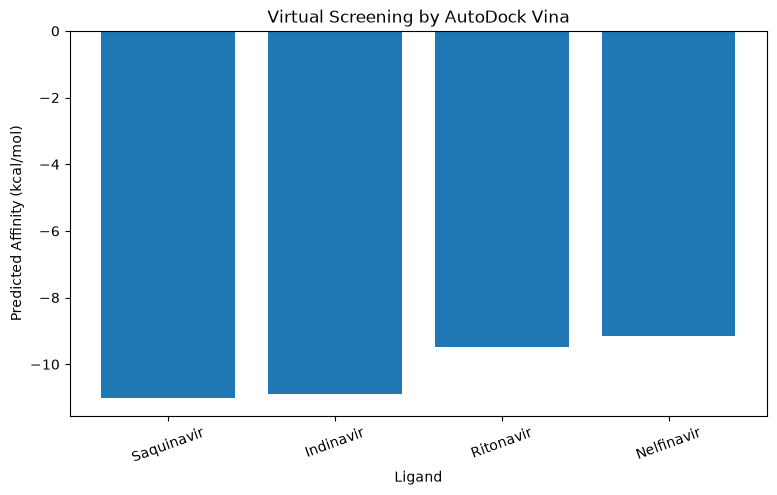

Top-ranked ligand:
Ligand                                                        Saquinavir
Best Affinity (kcal/mol)                                           -11.0
Docked Pose                 assignment04_docking/saquinavir_docked.pdbqt
Name: 0, dtype: object


In [ ]:
# Plot virtual screening scores

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    results_df["Ligand"],
    results_df["Best Affinity (kcal/mol)"]
)
plt.xlabel("Ligand")
plt.ylabel("Predicted Affinity (kcal/mol)")
plt.title("Virtual Screening by AutoDock Vina")
plt.xticks(rotation=20)
plt.show()

print("Top-ranked ligand:")
print(results_df.iloc[0])

## Step 10: Visualization

The generated `*_docked.pdbqt` files can be opened in PyMOL or UCSF Chimera together with the receptor structure to inspect:

- Hydrogen-bonding interactions
- Hydrophobic contacts
- Ligand orientation
- Binding-pocket occupancy
- Overall binding pose

The docking output should be visually inspected rather than relying only on the numerical score.

## Result

Molecular docking was performed between the selected protein target and multiple small-molecule ligands. The ligands were ranked according to their predicted AutoDock Vina binding affinity, demonstrating a basic structure-based virtual screening workflow.

## Conclusion

Thus, molecular docking and virtual screening were implemented successfully using a protein structure, prepared ligands, AutoDock Vina, and Meeko. The docking scores were used to rank the candidate compounds, and the top-ranked compound can be selected for further computational and experimental investigation.

In [ ]:
# Optional: package the docking results for download
import shutil

zip_path = shutil.make_archive(
    "Assignment04_docking_results",
    "zip",
    WORKDIR
)

print("Created:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Download the ZIP manually from the file browser.")

Created: /content/Assignment04_docking_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>